# AeroTrack — Part 6: Multi-Shot ReID and Retrieval Evaluation

## Purpose

This notebook tests whether using several gallery crops per person improves pretrained OSNet matching on VisDrone-MOT, without retraining the model.

We compare three strategies using the same later-frame query crops:

1. **Single-shot:** one representative earlier crop per identity.
2. **Multi-shot mean:** average three earlier crop embeddings into one identity prototype.
3. **Multi-shot max:** compare the query against all three earlier crops and keep the highest similarity for that identity.

Every identity contributes exactly three gallery crops. This keeps the number of gallery examples equal for all identities in the max-similarity comparison. Each identity contributes two or three query crops from a later period.

## Evaluation design

For each sequence-local `(sequence_id, target_id)`:
- Use ground-truth annotations to extract three earlier gallery crops.
- Use two or three later query crops, separated from the gallery period by a frame gap.
- Extract OSNet embeddings for all crops.
- Retrieve the correct identity from the gallery of that same sequence.
- Report Rank-1, Rank-5, Rank-10 and mAP.

We compare all three strategies on the exact same query crops.

## Important limitations

- This is an evaluation of ReID using ground-truth crops. It does not measure detector or tracker performance.
- VisDrone target IDs are only meaningful within their own sequence. We do not compare target IDs across different sequences.
- The OSNet checkpoint remains pretrained on MSMT17 general pedestrian imagery. We do not train or fine-tune it here.
- Cosine similarity is not a probability. High similarity does not prove identity.
- Results on these seven validation sequences are a development comparison, not proof of cross-video identity accuracy.

References:
- ReID package and OSNet: https://reid.roboflow.com/
- Model API and embedding extraction: https://reid.roboflow.com/api/model/

## Section 1 — Imports, paths and settings

The default dataset path matches the extracted folder structure you showed. Change `VISDRONE_ROOT` only if you moved the dataset.

In [1]:
from pathlib import Path
import re
import math
import time
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display
from reid import ReIDModel
from sklearn.metrics import roc_auc_score, average_precision_score

VISDRONE_ROOT = (
    Path.home()
    / "Downloads"
    / "VisDrone2019-MOT-val"
    / "VisDrone2019-MOT-val"
)

SEQUENCES_DIR = VISDRONE_ROOT / "sequences"
ANNOTATIONS_DIR = VISDRONE_ROOT / "annotations"

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs" / "part6_multishot_reid"
CROP_DIR = OUTPUT_DIR / "crops"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CROP_DIR.mkdir(parents=True, exist_ok=True)

# VisDrone ground-truth categories: 1=pedestrian, 2=people.
PERSON_CATEGORY_IDS = [1, 2]

# Keep reasonably visible person crops for the initial comparison.
MIN_BOX_WIDTH = 12
MIN_BOX_HEIGHT = 20
MAX_OCCLUSION = 1
MAX_TRUNCATION = 1

# Use exactly three gallery crops for every identity.
GALLERY_SHOTS = 3
MIN_QUERY_SHOTS = 2
MAX_QUERY_SHOTS = 3
MIN_GALLERY_QUERY_GAP_FRAMES = 15
CROP_MARGIN_RATIO = 0.04

REID_MODEL_NAME = "osnet_x1_0_msmt17_combineall"
EMBEDDING_BATCH_SIZE = 16

print("Dataset exists:", VISDRONE_ROOT.exists())
print("Sequences folder:", SEQUENCES_DIR.exists())
print("Annotations folder:", ANNOTATIONS_DIR.exists())

if torch.cuda.is_available():
    REID_DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    REID_DEVICE = "cpu"
    print("Using CPU")

print("ReID device:", REID_DEVICE)

Dataset exists: True
Sequences folder: True
Annotations folder: True
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
ReID device: cuda


## Section 2 — Find sequences, frames and annotation files

Each sequence is a folder of numbered image frames. Its ground-truth annotation file has the same base name.

In [2]:
if not SEQUENCES_DIR.exists() or not ANNOTATIONS_DIR.exists():
    raise FileNotFoundError(
        "VisDrone-MOT folders not found. Check VISDRONE_ROOT."
    )

sequence_dirs = sorted(
    p for p in SEQUENCES_DIR.iterdir() if p.is_dir()
)

sequence_data = {}

for sequence_dir in sequence_dirs:
    sequence_name = sequence_dir.name
    annotation_path = ANNOTATIONS_DIR / f"{sequence_name}.txt"

    if not annotation_path.exists():
        raise FileNotFoundError(annotation_path)

    image_paths = sorted(
        [
            p for p in sequence_dir.rglob("*")
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ],
        key=lambda p: p.as_posix()
    )

    frame_map = {}

    for image_path in image_paths:
        match = re.search(r"(\d+)$", image_path.stem)
        if match is None:
            raise ValueError(f"Cannot read frame number: {image_path.name}")
        frame_map[int(match.group(1))] = image_path

    if frame_map:
        sequence_data[sequence_name] = {
            "annotation_path": annotation_path,
            "frame_map": frame_map
        }

    print(
        f"{sequence_name}: {len(frame_map)} frames"
    )

print("Sequences ready:", len(sequence_data))

uav0000086_00000_v: 464 frames
uav0000117_02622_v: 349 frames
uav0000137_00458_v: 233 frames
uav0000182_00000_v: 363 frames
uav0000268_05773_v: 978 frames
uav0000305_00000_v: 184 frames
uav0000339_00001_v: 275 frames
Sequences ready: 7


## Section 3 — Read and filter ground-truth person annotations

The ten annotation fields are: frame, target ID, left, top, width, height, score, category, truncation and occlusion.

We keep valid pedestrian and people labels. Ground-truth target ID 0 is valid; only negative IDs are excluded. IDs remain sequence-local.

In [3]:
ANNOTATION_COLUMNS = [
    "frame_index", "target_id", "bbox_left", "bbox_top",
    "bbox_width", "bbox_height", "score", "object_category",
    "truncation", "occlusion"
]

annotation_tables = []

for sequence_name, info in sequence_data.items():
    df = pd.read_csv(
        info["annotation_path"],
        header=None,
        names=ANNOTATION_COLUMNS
    )

    if df.shape[1] != 10:
        raise ValueError(f"{sequence_name}: expected 10 annotation columns.")

    for column in ANNOTATION_COLUMNS:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    df = df.dropna(subset=ANNOTATION_COLUMNS).copy()

    for column in [
        "frame_index", "target_id", "score",
        "object_category", "truncation", "occlusion"
    ]:
        df[column] = df[column].astype(int)

    df["sequence_id"] = sequence_name
    annotation_tables.append(df)

annotations = pd.concat(annotation_tables, ignore_index=True)

person_annotations = annotations[
    (annotations["score"] == 1) &
    (annotations["target_id"] >= 0) &
    (annotations["object_category"].isin(PERSON_CATEGORY_IDS)) &
    (annotations["bbox_width"] >= MIN_BOX_WIDTH) &
    (annotations["bbox_height"] >= MIN_BOX_HEIGHT) &
    (annotations["occlusion"] <= MAX_OCCLUSION) &
    (annotations["truncation"] <= MAX_TRUNCATION)
].copy()

person_annotations["identity_key"] = (
    person_annotations["sequence_id"].astype(str)
    + "::target_"
    + person_annotations["target_id"].astype(str)
)

person_annotations["box_area"] = (
    person_annotations["bbox_width"] *
    person_annotations["bbox_height"]
)

person_annotations["crop_quality"] = (
    np.sqrt(person_annotations["box_area"].clip(lower=0))
    * (1.0 - 0.20 * person_annotations["occlusion"])
    * (1.0 - 0.10 * person_annotations["truncation"])
)

# Keep one ground-truth row per person per frame.
person_annotations = (
    person_annotations
    .sort_values(
        ["sequence_id", "target_id", "frame_index", "crop_quality"],
        ascending=[True, True, True, False]
    )
    .drop_duplicates(
        ["sequence_id", "target_id", "frame_index"],
        keep="first"
    )
    .copy()
)

print("All annotation rows:", len(annotations))
print("Valid person observations:", len(person_annotations))
print("Sequence-local person identities:", person_annotations["identity_key"].nunique())

display(
    person_annotations.groupby("sequence_id")
    .agg(
        observations=("target_id", "size"),
        identities=("identity_key", "nunique")
    )
    .reset_index()
)

All annotation rows: 118127
Valid person observations: 47435
Sequence-local person identities: 319


,sequence_id,observations,identities
0,uav0000086_00000_v,20307,72
1,uav0000117_02622_v,9189,96
2,uav0000137_00458_v,9234,81
3,uav0000182_00000_v,1168,24
4,uav0000268_05773_v,1839,6
5,uav0000305_00000_v,603,6
6,uav0000339_00001_v,5095,34


## Section 4 — Select multiple earlier and later observations per identity

We split each person's timeline into:
- An earlier gallery period.
- A later query period, starting at least 15 frames after the split.

We require at least three usable gallery observations and two query observations. We then select exactly three temporally spread gallery crops and up to three query crops.

This gives the multi-shot methods the same number of gallery images for every identity.

In [4]:
def select_temporal_samples(group, sample_count):
    # Divide the time-ordered observations into bins and choose the
    # highest-quality observation from each bin.
    group = group.sort_values("frame_index").reset_index(drop=True)

    if len(group) < sample_count:
        return []

    position_bins = np.array_split(
        np.arange(len(group)),
        sample_count
    )

    chosen_rows = []

    for positions in position_bins:
        if len(positions) == 0:
            continue

        time_bin = group.iloc[positions]
        best_index = time_bin["crop_quality"].idxmax()
        chosen_rows.append(time_bin.loc[best_index].to_dict())

    return chosen_rows


identity_samples = []

for identity_key, group in person_annotations.groupby("identity_key"):
    group = group.sort_values("frame_index").copy()

    unique_frames = np.sort(group["frame_index"].unique())

    if len(unique_frames) < GALLERY_SHOTS + MIN_QUERY_SHOTS:
        continue

    first_frame = int(unique_frames.min())
    last_frame = int(unique_frames.max())

    if last_frame - first_frame < MIN_GALLERY_QUERY_GAP_FRAMES:
        continue

    split_frame = (first_frame + last_frame) / 2.0

    gallery_candidates = group[
        group["frame_index"] <= split_frame
    ].copy()

    query_candidates = group[
        group["frame_index"] >= (
            split_frame + MIN_GALLERY_QUERY_GAP_FRAMES
        )
    ].copy()

    if len(gallery_candidates) < GALLERY_SHOTS:
        continue

    if len(query_candidates) < MIN_QUERY_SHOTS:
        continue

    gallery_selected = select_temporal_samples(
        gallery_candidates,
        GALLERY_SHOTS
    )

    query_sample_count = min(
        MAX_QUERY_SHOTS,
        len(query_candidates)
    )

    query_selected = select_temporal_samples(
        query_candidates,
        query_sample_count
    )

    if len(gallery_selected) != GALLERY_SHOTS:
        continue

    if len(query_selected) < MIN_QUERY_SHOTS:
        continue

    identity_samples.append({
        "identity_key": identity_key,
        "sequence_id": str(group["sequence_id"].iloc[0]),
        "target_id": int(group["target_id"].iloc[0]),
        "gallery": gallery_selected,
        "query": query_selected
    })

if len(identity_samples) < 2:
    raise RuntimeError(
        "Not enough identities meet the multi-shot requirements. "
        "Lower the frame gap or minimum observation requirements."
    )

print("Eligible identities:", len(identity_samples))
print("Gallery crops:", sum(len(x["gallery"]) for x in identity_samples))
print("Query crops:", sum(len(x["query"]) for x in identity_samples))

sample_summary = pd.DataFrame([
    {
        "sequence_id": x["sequence_id"],
        "target_id": x["target_id"],
        "identity_key": x["identity_key"],
        "gallery_shots": len(x["gallery"]),
        "query_shots": len(x["query"]),
        "gallery_last_frame": max(int(r["frame_index"]) for r in x["gallery"]),
        "query_first_frame": min(int(r["frame_index"]) for r in x["query"])
    }
    for x in identity_samples
])

display(
    sample_summary.groupby("sequence_id")
    .agg(
        identities=("identity_key", "count"),
        gallery_crops=("gallery_shots", "sum"),
        query_crops=("query_shots", "sum")
    )
    .reset_index()
)

Eligible identities: 275
Gallery crops: 825
Query crops: 823


,sequence_id,identities,gallery_crops,query_crops
0,uav0000086_00000_v,66,198,198
1,uav0000117_02622_v,88,264,263
2,uav0000137_00458_v,65,195,194
3,uav0000182_00000_v,13,39,39
4,uav0000268_05773_v,6,18,18
5,uav0000305_00000_v,4,12,12
6,uav0000339_00001_v,33,99,99


## Section 5 — Extract ground-truth gallery and query crops

The crop coordinates come directly from VisDrone annotations. Each crop is saved under its sequence-local identity folder.

In [5]:
crop_records = []

for item in identity_samples:
    sequence_name = item["sequence_id"]
    frame_map = sequence_data[sequence_name]["frame_map"]

    for role in ["gallery", "query"]:
        for shot_number, annotation in enumerate(item[role], start=1):
            frame_number = int(annotation["frame_index"])

            if frame_number not in frame_map:
                continue

            frame_path = frame_map[frame_number]
            frame = cv2.imread(str(frame_path))

            if frame is None:
                continue

            x = float(annotation["bbox_left"])
            y = float(annotation["bbox_top"])
            w = float(annotation["bbox_width"])
            h = float(annotation["bbox_height"])

            mx = int(w * CROP_MARGIN_RATIO)
            my = int(h * CROP_MARGIN_RATIO)

            left = max(0, int(np.floor(x)) - mx)
            top = max(0, int(np.floor(y)) - my)
            right = min(frame.shape[1], int(np.ceil(x + w)) + mx)
            bottom = min(frame.shape[0], int(np.ceil(y + h)) + my)

            crop = frame[top:bottom, left:right]

            if crop.size == 0:
                continue

            target_id = int(item["target_id"])
            folder = (
                CROP_DIR / sequence_name / f"target_{target_id:05d}"
            )
            folder.mkdir(parents=True, exist_ok=True)

            crop_path = folder / (
                f"{role}_{shot_number:02d}_frame_{frame_number:07d}.jpg"
            )

            if not cv2.imwrite(str(crop_path), crop):
                continue

            crop_records.append({
                "sequence_id": sequence_name,
                "target_id": target_id,
                "identity_key": item["identity_key"],
                "role": role,
                "shot_number": shot_number,
                "frame_index": frame_number,
                "crop_width": int(crop.shape[1]),
                "crop_height": int(crop.shape[0]),
                "crop_quality": float(annotation["crop_quality"]),
                "crop_path": str(crop_path)
            })

crop_manifest = pd.DataFrame(crop_records)

if crop_manifest.empty:
    raise RuntimeError("No person crops could be extracted.")

# Keep only identities with all 3 gallery crops and at least 2 query crops.
counts = (
    crop_manifest.groupby(["identity_key", "role"])
    .size()
    .unstack(fill_value=0)
)

valid_identities = counts[
    (counts.get("gallery", 0) == GALLERY_SHOTS) &
    (counts.get("query", 0) >= MIN_QUERY_SHOTS)
].index.tolist()

crop_manifest = crop_manifest[
    crop_manifest["identity_key"].isin(valid_identities)
].reset_index(drop=True)

if crop_manifest.empty:
    raise RuntimeError(
        "No identities remained after checking extracted gallery/query crops."
    )

CROP_MANIFEST_PATH = OUTPUT_DIR / "multishot_crop_manifest.csv"
crop_manifest.to_csv(CROP_MANIFEST_PATH, index=False)

print("Identities retained:", crop_manifest["identity_key"].nunique())
print("Gallery crops:", int((crop_manifest["role"] == "gallery").sum()))
print("Query crops:", int((crop_manifest["role"] == "query").sum()))
print("Crop manifest:", CROP_MANIFEST_PATH)

display(
    crop_manifest.groupby(["sequence_id", "role"])
    .size()
    .unstack(fill_value=0)
)

Identities retained: 275
Gallery crops: 825
Query crops: 823
Crop manifest: c:\Users\anyan\source\repos\AeroTrack\outputs\part6_multishot_reid\multishot_crop_manifest.csv


role,gallery,query
sequence_id,,
uav0000086_00000_v,198,198
uav0000117_02622_v,264,263
uav0000137_00458_v,195,194
uav0000182_00000_v,39,39
uav0000268_05773_v,18,18
uav0000305_00000_v,12,12
uav0000339_00001_v,99,99


## Section 6 — Inspect the selected multi-shot crops

Each row in this gallery represents one identity. The first three columns are earlier gallery crops. The next columns are later query crops.

The same ground-truth identity should appear across its row, but at different moments in the sequence.

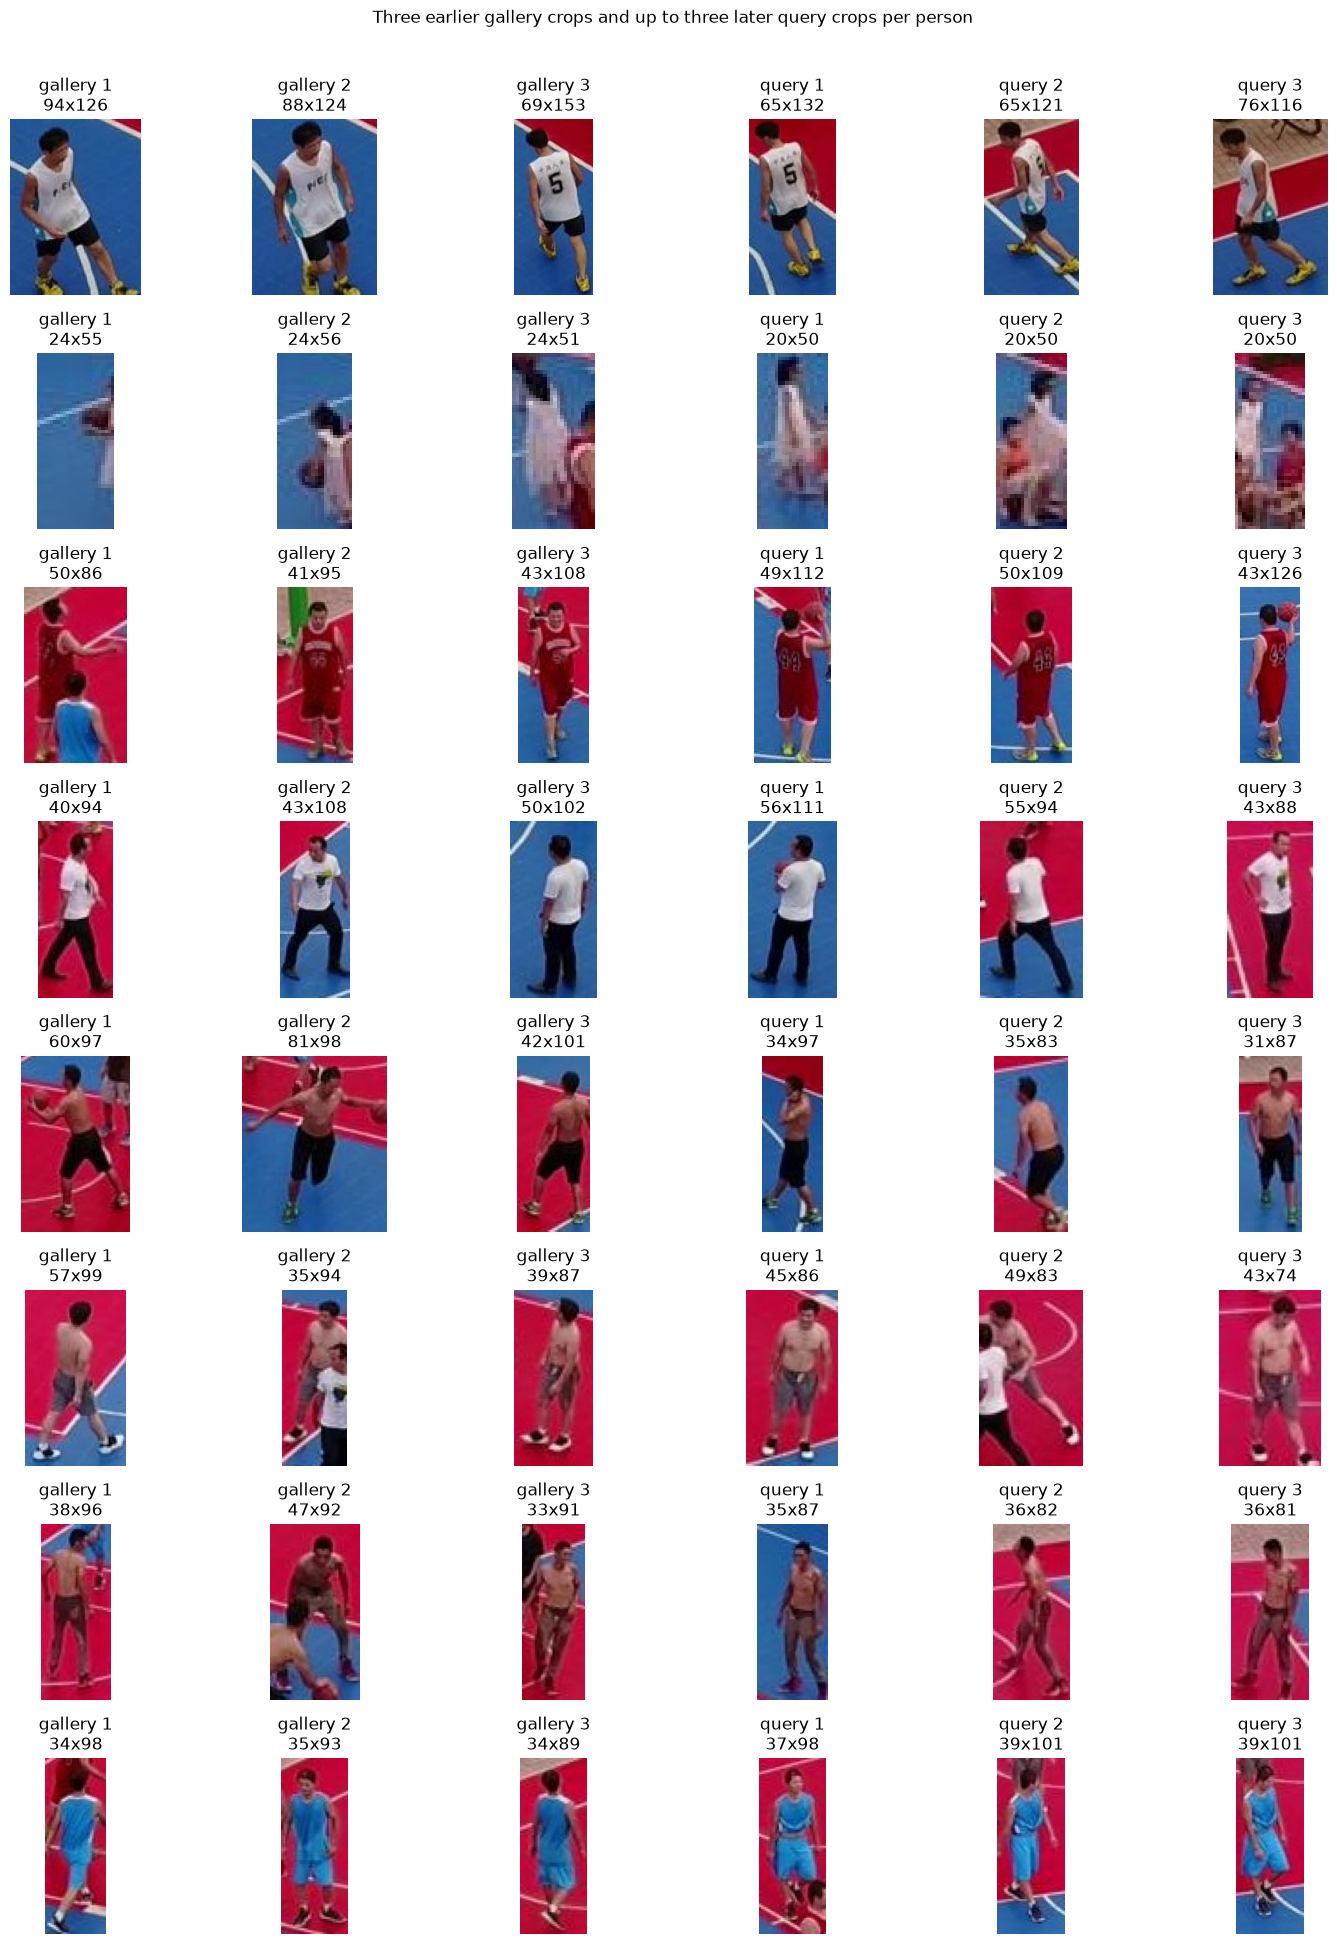

In [6]:
preview_keys = (
    crop_manifest["identity_key"]
    .drop_duplicates()
    .head(8)
    .tolist()
)

preview_rows = crop_manifest[
    crop_manifest["identity_key"].isin(preview_keys)
]

fig, axes = plt.subplots(
    len(preview_keys),
    GALLERY_SHOTS + MAX_QUERY_SHOTS,
    figsize=(15, max(3, len(preview_keys) * 2.4))
)

if len(preview_keys) == 1:
    axes = np.array([axes])

for row_index, identity_key in enumerate(preview_keys):
    group = preview_rows[
        preview_rows["identity_key"] == identity_key
    ]

    for col_index in range(GALLERY_SHOTS + MAX_QUERY_SHOTS):
        ax = axes[row_index, col_index]
        ax.axis("off")

        if col_index < GALLERY_SHOTS:
            role = "gallery"
            shot_no = col_index + 1
        else:
            role = "query"
            shot_no = col_index - GALLERY_SHOTS + 1

        found = group[
            (group["role"] == role) &
            (group["shot_number"] == shot_no)
        ]

        if found.empty:
            continue

        row = found.iloc[0]
        image = cv2.imread(row["crop_path"])

        if image is None:
            continue

        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(
            f"{role} {shot_no}\n"
            f"{row['crop_width']}x{row['crop_height']}"
        )

    axes[row_index, 0].set_ylabel(
        identity_key,
        rotation=0,
        labelpad=85,
        va="center"
    )

plt.suptitle(
    "Three earlier gallery crops and up to three later query crops per person",
    y=1.01
)
plt.tight_layout()
plt.show()

## Section 7 — Load pretrained OSNet and extract embeddings

We use the same pretrained OSNet checkpoint as Part 5. We are generating appearance embeddings only; there is no training or fine-tuning.

In [7]:
reid_model = ReIDModel.from_pretrained(
    REID_MODEL_NAME,
    device=REID_DEVICE
)

crop_paths = crop_manifest["crop_path"].tolist()

embedding_start = time.time()

crop_embeddings = reid_model.extract_embeddings_from_paths(
    crop_paths,
    batch_size=EMBEDDING_BATCH_SIZE,
    num_workers=0
)

crop_embeddings = np.asarray(crop_embeddings, dtype=np.float32)

if crop_embeddings.ndim != 2:
    raise ValueError(f"Expected a 2D embedding matrix, got {crop_embeddings.shape}")

if crop_embeddings.shape[0] != len(crop_manifest):
    raise ValueError("Embedding count does not match crop count.")

if not np.isfinite(crop_embeddings).all():
    raise ValueError("OSNet returned non-finite embedding values.")

# Normalize each crop embedding for cosine similarity.
norms = np.linalg.norm(crop_embeddings, axis=1, keepdims=True)
crop_embeddings = crop_embeddings / np.maximum(norms, 1e-12)

embedding_seconds = time.time() - embedding_start
crop_manifest["embedding_index"] = np.arange(len(crop_manifest))

print("Embedding matrix:", crop_embeddings.shape)
print("Embedding dimensions:", crop_embeddings.shape[1])
print("Embedding extraction time:", round(embedding_seconds, 2), "seconds")

C:\Users\anyan\AppData\Local\Temp\ipykernel_17916\1632053990.py:1: UserWarning: The osnet_x1_0_msmt17_combineall weights were trained on MSMT17 pedestrian images. Performance may degrade significantly on non-person objects (vehicles, animals, products, etc.). Pass a domain-specific checkpoint via `ReIDModel.from_pretrained(source, architecture=...)` for other use cases.
  reid_model = ReIDModel.from_pretrained(


Embedding matrix: (1648, 512)
Embedding dimensions: 512
Embedding extraction time: 36.89 seconds


## Section 8 — Build single-shot and multi-shot gallery representations

For each person identity:
- Single-shot uses the highest-quality one of the three gallery crops.
- Multi-shot mean averages the three normalized gallery embeddings and normalizes the result.
- Multi-shot max retains all three gallery embeddings and later uses the highest similarity to any of them.

Every identity has exactly three gallery crops, so max similarity is compared fairly across identities.

In [8]:
gallery_data = {}

for sequence_name in sorted(crop_manifest["sequence_id"].unique()):
    gallery_data[sequence_name] = {}

    sequence_gallery = crop_manifest[
        (crop_manifest["sequence_id"] == sequence_name) &
        (crop_manifest["role"] == "gallery")
    ]

    for identity_key, group in sequence_gallery.groupby("identity_key"):
        # Highest-quality crop is the single-shot representative.
        group = group.sort_values("crop_quality", ascending=False)

        indices = group["embedding_index"].astype(int).to_numpy()
        vectors = crop_embeddings[indices]

        single_vector = vectors[0]

        mean_vector = vectors.mean(axis=0)
        mean_norm = np.linalg.norm(mean_vector)
        mean_vector = mean_vector / max(float(mean_norm), 1e-12)

        gallery_data[sequence_name][identity_key] = {
            "single": single_vector,
            "mean": mean_vector,
            "shots": vectors
        }

gallery_count_table = pd.DataFrame([
    {
        "sequence_id": sequence_name,
        "identities": len(identity_dict),
        "gallery_crops": sum(
            item["shots"].shape[0]
            for item in identity_dict.values()
        )
    }
    for sequence_name, identity_dict in gallery_data.items()
])

display(gallery_count_table)

,sequence_id,identities,gallery_crops
0,uav0000086_00000_v,66,198
1,uav0000117_02622_v,88,264
2,uav0000137_00458_v,65,195
3,uav0000182_00000_v,13,39
4,uav0000268_05773_v,6,18
5,uav0000305_00000_v,4,12
6,uav0000339_00001_v,33,99


## Section 9 — Evaluate single-shot and multi-shot retrieval

Each later query crop is compared against every gallery identity from the same sequence.

We calculate:
- `single_shot`: similarity to the one best-quality gallery crop.
- `multi_mean`: similarity to the averaged three-crop prototype.
- `multi_max`: maximum similarity across the three gallery crops.

Rank-1, Rank-5 and Rank-10 indicate whether the correct identity appears first, in the top five, or in the top ten. With one gallery prototype per identity, AP for a query is the reciprocal rank of its correct identity.

In [9]:
query_manifest = crop_manifest[
    crop_manifest["role"] == "query"
].copy()

query_result_rows = []
verification_rows = []

for _, query_row in query_manifest.iterrows():
    sequence_name = str(query_row["sequence_id"])
    query_identity = str(query_row["identity_key"])
    query_vector = crop_embeddings[int(query_row["embedding_index"])]

    identities = gallery_data.get(sequence_name, {})

    if query_identity not in identities or len(identities) < 2:
        continue

    gallery_keys = sorted(identities.keys())

    score_lists = {
        "single_shot": [],
        "multi_mean": [],
        "multi_max": []
    }

    for gallery_identity in gallery_keys:
        item = identities[gallery_identity]

        score_lists["single_shot"].append(
            float(query_vector @ item["single"])
        )
        score_lists["multi_mean"].append(
            float(query_vector @ item["mean"])
        )
        score_lists["multi_max"].append(
            float(np.max(item["shots"] @ query_vector))
        )

    positive_index = gallery_keys.index(query_identity)

    for strategy, score_list in score_lists.items():
        scores = np.asarray(score_list, dtype=np.float32)
        ranking = np.argsort(scores)[::-1]

        correct_rank = int(np.where(ranking == positive_index)[0][0]) + 1
        sorted_scores = scores[ranking]
        top_identity = gallery_keys[int(ranking[0])]

        second_score = (
            float(sorted_scores[1])
            if len(sorted_scores) > 1 else np.nan
        )

        query_result_rows.append({
            "sequence_id": sequence_name,
            "identity_key": query_identity,
            "target_id": int(query_row["target_id"]),
            "query_frame": int(query_row["frame_index"]),
            "query_shot": int(query_row["shot_number"]),
            "strategy": strategy,
            "rank": correct_rank,
            "rank1": int(correct_rank == 1),
            "rank5": int(correct_rank <= 5),
            "rank10": int(correct_rank <= 10),
            "average_precision": 1.0 / correct_rank,
            "correct_similarity": float(scores[positive_index]),
            "top_similarity": float(sorted_scores[0]),
            "second_similarity": second_score,
            "margin": (
                float(sorted_scores[0] - second_score)
                if np.isfinite(second_score) else np.nan
            ),
            "top_candidate_identity": top_identity,
            "top_candidate_correct": top_identity == query_identity
        })

        # Pairwise verification labels for each strategy.
        for gallery_index, gallery_identity in enumerate(gallery_keys):
            verification_rows.append({
                "sequence_id": sequence_name,
                "query_identity": query_identity,
                "gallery_identity": gallery_identity,
                "strategy": strategy,
                "same_identity": int(gallery_identity == query_identity),
                "cosine_similarity": float(scores[gallery_index])
            })

query_results = pd.DataFrame(query_result_rows)
verification_df = pd.DataFrame(verification_rows)

if query_results.empty:
    raise RuntimeError("No query results were generated.")

print("Query crops evaluated:", query_manifest.shape[0])
print("Query-strategy rows evaluated:", len(query_results))

display(query_results.head(10))

Query crops evaluated: 823
Query-strategy rows evaluated: 2469


,sequence_id,identity_key,target_id,query_frame,query_shot,strategy,rank,rank1,rank5,rank10,average_precision,correct_similarity,top_similarity,second_similarity,margin,top_candidate_identity,top_candidate_correct
0,uav0000086_00000_v,uav0000086_00000_v::target_0,0,174,1,single_shot,1,1,1,1,1.000000,0.701721,0.701721,0.699515,0.002206,uav0000086_00000_v::target_0,True
1,uav0000086_00000_v,uav0000086_00000_v::target_0,0,174,1,multi_mean,1,1,1,1,1.000000,0.821581,0.821581,0.724989,0.096591,uav0000086_00000_v::target_0,True
2,uav0000086_00000_v,uav0000086_00000_v::target_0,0,174,1,multi_max,1,1,1,1,1.000000,0.867891,0.867891,0.718190,0.149700,uav0000086_00000_v::target_0,True
3,uav0000086_00000_v,uav0000086_00000_v::target_0,0,191,2,single_shot,7,0,0,1,0.142857,0.608154,0.668216,0.659753,0.008463,uav0000086_00000_v::target_52,False
4,uav0000086_00000_v,uav0000086_00000_v::target_0,0,191,2,multi_mean,5,0,1,1,0.200000,0.686532,0.734078,0.718518,0.015560,uav0000086_00000_v::target_13,False
5,uav0000086_00000_v,uav0000086_00000_v::target_0,0,191,2,multi_max,1,1,1,1,1.000000,0.681244,0.681244,0.669578,0.011666,uav0000086_00000_v::target_0,True
6,uav0000086_00000_v,uav0000086_00000_v::target_0,0,208,3,single_shot,3,0,1,1,0.333333,0.648438,0.685419,0.669453,0.015966,uav0000086_00000_v::target_52,False
7,uav0000086_00000_v,uav0000086_00000_v::target_0,0,208,3,multi_mean,1,1,1,1,1.000000,0.740474,0.740474,0.735642,0.004832,uav0000086_00000_v::target_0,True
8,uav0000086_00000_v,uav0000086_00000_v::target_0,0,208,3,multi_max,1,1,1,1,1.000000,0.737026,0.737026,0.685419,0.051607,uav0000086_00000_v::target_0,True
9,uav0000086_00000_v,uav0000086_00000_v::target_1,1,197,1,single_shot,1,1,1,1,1.000000,0.742814,0.742814,0.730467,0.012348,uav0000086_00000_v::target_1,True


## Section 10 — Compare the results

This is the main result of Part 6. All strategies use the same query images and the same sequence-local identity labels.

We report:
- Micro average: all query crops pooled together.
- Macro average: average of the per-sequence metrics, giving each sequence equal weight.

In [10]:
metric_columns = [
    "rank1", "rank5", "rank10", "average_precision"
]

overall_metrics = (
    query_results.groupby("strategy")[metric_columns]
    .mean()
    .reset_index()
    .rename(columns={
        "rank1": "Rank-1",
        "rank5": "Rank-5",
        "rank10": "Rank-10",
        "average_precision": "mAP"
    })
)

query_counts = (
    query_results.groupby("strategy")
    .size()
    .rename("queries")
    .reset_index()
)

overall_metrics = overall_metrics.merge(
    query_counts,
    on="strategy",
    how="left"
)

sequence_metrics = (
    query_results.groupby(["sequence_id", "strategy"])[metric_columns]
    .mean()
    .reset_index()
    .rename(columns={
        "rank1": "Rank-1",
        "rank5": "Rank-5",
        "rank10": "Rank-10",
        "average_precision": "mAP"
    })
)

macro_metrics = (
    sequence_metrics.groupby("strategy")[
        ["Rank-1", "Rank-5", "Rank-10", "mAP"]
    ]
    .mean()
    .reset_index()
)

print("OVERALL MICRO-AVERAGED RESULTS")
display(
    overall_metrics[
        ["strategy", "queries", "Rank-1", "Rank-5", "Rank-10", "mAP"]
    ].sort_values("Rank-1", ascending=False)
)

print("PER-SEQUENCE RESULTS")
display(sequence_metrics)

print("MACRO-AVERAGED RESULTS")
display(macro_metrics)

OVERALL MICRO-AVERAGED RESULTS


,strategy,queries,Rank-1,Rank-5,Rank-10,mAP
0,multi_max,823,0.673147,0.851762,0.902795,0.758593
1,multi_mean,823,0.668287,0.857837,0.916160,0.755249
2,single_shot,823,0.557716,0.773998,0.839611,0.657354


PER-SEQUENCE RESULTS


,sequence_id,strategy,Rank-1,Rank-5,Rank-10,mAP
0,uav0000086_00000_v,multi_max,0.696970,0.868687,0.919192,0.775972
1,uav0000086_00000_v,multi_mean,0.656566,0.858586,0.919192,0.752376
2,uav0000086_00000_v,single_shot,0.520202,0.747475,0.838384,0.630656
3,uav0000117_02622_v,multi_max,0.513308,0.703422,0.783270,0.610386
4,uav0000117_02622_v,multi_mean,0.528517,0.726236,0.825095,0.623830
5,uav0000117_02622_v,single_shot,0.387833,0.600760,0.684411,0.491041
6,uav0000137_00458_v,multi_max,0.850515,0.948454,0.969072,0.899840
7,uav0000137_00458_v,multi_mean,0.855670,0.943299,0.963918,0.896702
8,uav0000137_00458_v,single_shot,0.788660,0.907216,0.943299,0.842217
9,uav0000182_00000_v,multi_max,0.666667,0.923077,0.974359,0.791555


MACRO-AVERAGED RESULTS


,strategy,Rank-1,Rank-5,Rank-10,mAP
0,multi_max,0.648295,0.913305,0.949413,0.768323
1,multi_mean,0.656976,0.919491,0.958315,0.769385
2,single_shot,0.559262,0.863777,0.912850,0.687974


## Section 11 — Visual comparison of retrieval metrics

The bars show whether multi-shot mean or max pooling improves on the single-shot gallery baseline.

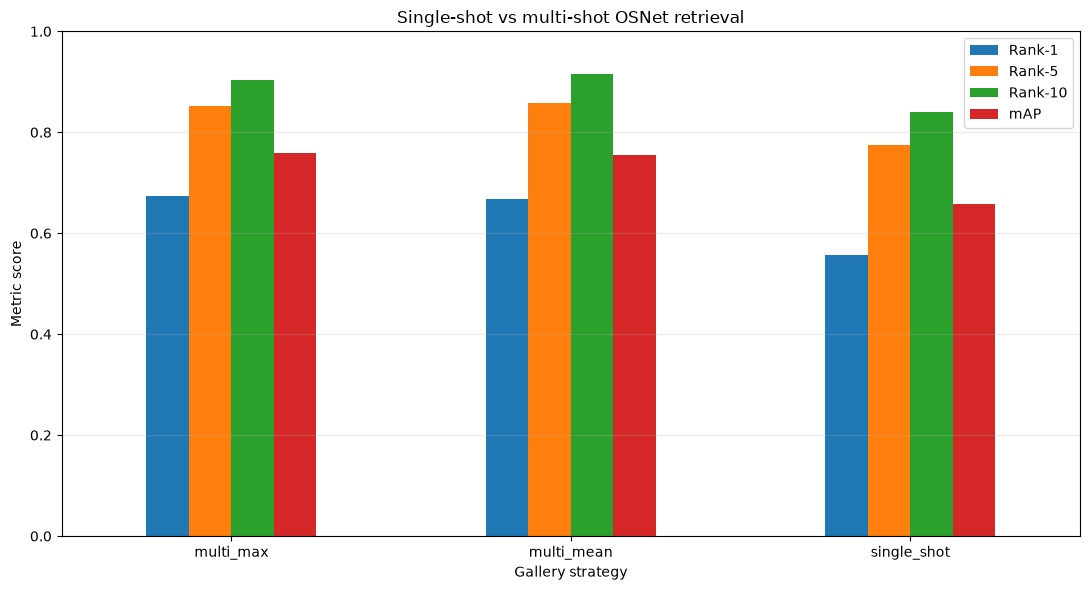

In [11]:
plot_df = overall_metrics.set_index("strategy")[
    ["Rank-1", "Rank-5", "Rank-10", "mAP"]
]

plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Single-shot vs multi-shot OSNet retrieval")
plt.ylabel("Metric score")
plt.xlabel("Gallery strategy")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Section 12 — Threshold diagnostics

This compares same-identity and different-identity query/gallery pairs for each gallery strategy. We calculate ROC AUC, pairwise average precision, precision, recall and F1 at several similarity thresholds.

These diagnostics help show the false-match trade-off. They do not create a universal identity threshold.

In [12]:
threshold_rows = []
verification_summary_rows = []

for strategy in ["single_shot", "multi_mean", "multi_max"]:
    subset = verification_df[
        verification_df["strategy"] == strategy
    ]

    labels = subset["same_identity"].to_numpy()
    scores = subset["cosine_similarity"].to_numpy()

    if len(np.unique(labels)) == 2:
        roc_auc = float(roc_auc_score(labels, scores))
        pair_ap = float(average_precision_score(labels, scores))
    else:
        roc_auc = np.nan
        pair_ap = np.nan

    verification_summary_rows.append({
        "strategy": strategy,
        "pairwise_ROC_AUC": roc_auc,
        "pairwise_average_precision": pair_ap,
        "positive_pairs": int(labels.sum()),
        "total_pairs": int(len(labels))
    })

    for threshold in [0.50, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]:
        predicted = scores >= threshold

        tp = int(np.sum(predicted & (labels == 1)))
        fp = int(np.sum(predicted & (labels == 0)))
        fn = int(np.sum((~predicted) & (labels == 1)))
        tn = int(np.sum((~predicted) & (labels == 0)))

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )

        threshold_rows.append({
            "strategy": strategy,
            "threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "precision": precision,
            "recall": recall,
            "F1": f1
        })

verification_summary = pd.DataFrame(verification_summary_rows)
threshold_metrics = pd.DataFrame(threshold_rows)

print("PAIRWISE VERIFICATION SUMMARY")
display(verification_summary)

print("THRESHOLD TRADE-OFFS")
display(threshold_metrics)

PAIRWISE VERIFICATION SUMMARY


,strategy,pairwise_ROC_AUC,pairwise_average_precision,positive_pairs,total_pairs
0,single_shot,0.911605,0.416177,823,52752
1,multi_mean,0.942857,0.496404,823,52752
2,multi_max,0.939462,0.477824,823,52752


THRESHOLD TRADE-OFFS


,strategy,threshold,TP,FP,FN,TN,precision,recall,F1
0,single_shot,0.50,718,12531,105,39398,0.054193,0.872418,0.102047
1,single_shot,0.60,585,2999,238,48930,0.163225,0.710814,0.265487
2,single_shot,0.65,489,1190,334,50739,0.291245,0.594168,0.390887
3,single_shot,0.70,383,428,440,51501,0.472256,0.465371,0.468788
4,single_shot,0.75,274,144,549,51785,0.655502,0.332928,0.441579
5,single_shot,0.80,157,65,666,51864,0.707207,0.190765,0.300478
6,single_shot,0.85,65,25,758,51904,0.722222,0.078979,0.142388
7,single_shot,0.90,10,0,813,51929,1.000000,0.012151,0.024010
8,multi_mean,0.50,792,21328,31,30601,0.035805,0.962333,0.069041
9,multi_mean,0.60,732,7110,91,44819,0.093344,0.889429,0.168956


## Section 13 — Review examples where multi-shot helps or hurts

We find query examples where:
- Multi-shot mean ranks the correct person first but single-shot does not.
- Single-shot succeeds but multi-shot mean fails.
- Multi-shot max produces a different result from multi-shot mean.

These examples help us understand whether averaging multiple views is useful for the actual aerial crops.

In [13]:
comparison_pivot = query_results.pivot_table(
    index=[
        "sequence_id", "identity_key", "query_frame", "query_shot"
    ],
    columns="strategy",
    values="rank"
).reset_index()

comparison_pivot.columns.name = None

comparison_pivot["mean_improved_rank1"] = (
    (comparison_pivot["multi_mean"] == 1) &
    (comparison_pivot["single_shot"] != 1)
)

comparison_pivot["single_better_rank1"] = (
    (comparison_pivot["single_shot"] == 1) &
    (comparison_pivot["multi_mean"] != 1)
)

print("Cases where multi-shot mean reaches Rank-1 and single-shot does not:")
display(
    comparison_pivot[
        comparison_pivot["mean_improved_rank1"]
    ].head(20)
)

print("Cases where single-shot reaches Rank-1 and multi-shot mean does not:")
display(
    comparison_pivot[
        comparison_pivot["single_better_rank1"]
    ].head(20)
)

print("Cases where multi-shot max differs from multi-shot mean:")
display(
    comparison_pivot[
        comparison_pivot["multi_max"] != comparison_pivot["multi_mean"]
    ].head(20)
)

Cases where multi-shot mean reaches Rank-1 and single-shot does not:


,sequence_id,identity_key,query_frame,query_shot,multi_max,multi_mean,single_shot,mean_improved_rank1,single_better_rank1
2,uav0000086_00000_v,uav0000086_00000_v::target_0,208,3,1.0,1.0,3.0,True,False
11,uav0000086_00000_v,uav0000086_00000_v::target_12,441,3,1.0,1.0,5.0,True,False
15,uav0000086_00000_v,uav0000086_00000_v::target_14,293,1,1.0,1.0,5.0,True,False
20,uav0000086_00000_v,uav0000086_00000_v::target_15,445,3,1.0,1.0,8.0,True,False
28,uav0000086_00000_v,uav0000086_00000_v::target_18,343,2,1.0,1.0,11.0,True,False
29,uav0000086_00000_v,uav0000086_00000_v::target_18,445,3,6.0,1.0,6.0,True,False
34,uav0000086_00000_v,uav0000086_00000_v::target_2,243,2,1.0,1.0,8.0,True,False
35,uav0000086_00000_v,uav0000086_00000_v::target_2,310,3,1.0,1.0,12.0,True,False
56,uav0000086_00000_v,uav0000086_00000_v::target_27,463,3,1.0,1.0,2.0,True,False
61,uav0000086_00000_v,uav0000086_00000_v::target_29,328,2,3.0,1.0,3.0,True,False


Cases where single-shot reaches Rank-1 and multi-shot mean does not:


,sequence_id,identity_key,query_frame,query_shot,multi_max,multi_mean,single_shot,mean_improved_rank1,single_better_rank1
3,uav0000086_00000_v,uav0000086_00000_v::target_1,197,1,2.0,2.0,1.0,False,True
30,uav0000086_00000_v,uav0000086_00000_v::target_19,363,1,1.0,2.0,1.0,False,True
51,uav0000086_00000_v,uav0000086_00000_v::target_26,277,1,2.0,2.0,1.0,False,True
91,uav0000086_00000_v,uav0000086_00000_v::target_4,242,2,1.0,2.0,1.0,False,True
92,uav0000086_00000_v,uav0000086_00000_v::target_4,322,3,1.0,2.0,1.0,False,True
113,uav0000086_00000_v,uav0000086_00000_v::target_46,411,3,2.0,2.0,1.0,False,True
129,uav0000086_00000_v,uav0000086_00000_v::target_53,302,1,1.0,2.0,1.0,False,True
162,uav0000086_00000_v,uav0000086_00000_v::target_66,392,1,1.0,2.0,1.0,False,True
212,uav0000117_02622_v,uav0000117_02622_v::target_102,139,3,3.0,3.0,1.0,False,True
271,uav0000117_02622_v,uav0000117_02622_v::target_13,322,2,5.0,6.0,1.0,False,True


Cases where multi-shot max differs from multi-shot mean:


,sequence_id,identity_key,query_frame,query_shot,multi_max,multi_mean,single_shot,mean_improved_rank1,single_better_rank1
1,uav0000086_00000_v,uav0000086_00000_v::target_0,191,2,1.0,5.0,7.0,False,False
4,uav0000086_00000_v,uav0000086_00000_v::target_1,226,2,9.0,10.0,6.0,False,False
5,uav0000086_00000_v,uav0000086_00000_v::target_1,275,3,21.0,15.0,18.0,False,False
8,uav0000086_00000_v,uav0000086_00000_v::target_11,433,3,3.0,6.0,2.0,False,False
10,uav0000086_00000_v,uav0000086_00000_v::target_12,326,2,1.0,5.0,19.0,False,False
12,uav0000086_00000_v,uav0000086_00000_v::target_13,295,1,2.0,3.0,20.0,False,False
13,uav0000086_00000_v,uav0000086_00000_v::target_13,340,2,1.0,2.0,23.0,False,False
14,uav0000086_00000_v,uav0000086_00000_v::target_13,458,3,1.0,2.0,22.0,False,False
16,uav0000086_00000_v,uav0000086_00000_v::target_14,337,2,10.0,9.0,19.0,False,False
17,uav0000086_00000_v,uav0000086_00000_v::target_14,432,3,4.0,2.0,2.0,False,False


## Section 14 — Save results

Main files saved under `outputs/part6_multishot_reid/`:
- `multishot_crop_manifest.csv`
- `multishot_osnet_embeddings.npz`
- `multishot_query_results.csv`
- `multishot_overall_metrics.csv`
- `multishot_sequence_metrics.csv`
- `multishot_macro_metrics.csv`
- `multishot_verification_pairs.csv`
- `multishot_verification_summary.csv`
- `multishot_threshold_metrics.csv`
- `multishot_summary.json`

In [14]:
crop_manifest.to_csv(
    OUTPUT_DIR / "multishot_crop_manifest.csv",
    index=False
)

query_results.to_csv(
    OUTPUT_DIR / "multishot_query_results.csv",
    index=False
)

overall_metrics.to_csv(
    OUTPUT_DIR / "multishot_overall_metrics.csv",
    index=False
)

sequence_metrics.to_csv(
    OUTPUT_DIR / "multishot_sequence_metrics.csv",
    index=False
)

macro_metrics.to_csv(
    OUTPUT_DIR / "multishot_macro_metrics.csv",
    index=False
)

verification_df.to_csv(
    OUTPUT_DIR / "multishot_verification_pairs.csv",
    index=False
)

verification_summary.to_csv(
    OUTPUT_DIR / "multishot_verification_summary.csv",
    index=False
)

threshold_metrics.to_csv(
    OUTPUT_DIR / "multishot_threshold_metrics.csv",
    index=False
)

np.savez_compressed(
    OUTPUT_DIR / "multishot_osnet_embeddings.npz",
    embeddings=crop_embeddings.astype(np.float32),
    identity_keys=crop_manifest["identity_key"].to_numpy(dtype=str),
    sequence_ids=crop_manifest["sequence_id"].to_numpy(dtype=str),
    roles=crop_manifest["role"].to_numpy(dtype=str),
    crop_paths=crop_manifest["crop_path"].to_numpy(dtype=str)
)

best_by_rank1 = overall_metrics.sort_values(
    "Rank-1", ascending=False
).iloc[0]

summary = {
    "sequences": int(crop_manifest["sequence_id"].nunique()),
    "identities": int(crop_manifest["identity_key"].nunique()),
    "gallery_crops": int((crop_manifest["role"] == "gallery").sum()),
    "query_crops": int((crop_manifest["role"] == "query").sum()),
    "embedding_dimensions": int(crop_embeddings.shape[1]),
    "embedding_time_seconds": float(embedding_seconds),
    "best_strategy_by_rank1": str(best_by_rank1["strategy"]),
    "overall_metrics": overall_metrics.to_dict(orient="records"),
    "note": (
        "Within-sequence temporal ReID evaluation using VisDrone ground truth. "
        "Compare strategies only on this same validation protocol. "
        "The results do not establish cross-video identity accuracy."
    )
}

with open(
    OUTPUT_DIR / "multishot_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=2)

print("Saved all results to:", OUTPUT_DIR)
display(pd.DataFrame([{
    "sequences": summary["sequences"],
    "identities": summary["identities"],
    "gallery_crops": summary["gallery_crops"],
    "query_crops": summary["query_crops"],
    "embedding_dimensions": summary["embedding_dimensions"],
    "best_strategy_by_rank1": summary["best_strategy_by_rank1"]
}]))
display(overall_metrics)

Saved all results to: c:\Users\anyan\source\repos\AeroTrack\outputs\part6_multishot_reid


,sequences,identities,gallery_crops,query_crops,embedding_dimensions,best_strategy_by_rank1
0,7,275,825,823,512,multi_max


,strategy,Rank-1,Rank-5,Rank-10,mAP,queries
0,multi_max,0.673147,0.851762,0.902795,0.758593,823
1,multi_mean,0.668287,0.857837,0.916160,0.755249,823
2,single_shot,0.557716,0.773998,0.839611,0.657354,823


## Section 15 — How to interpret the experiment and what to send back

### How to read the comparison

- If `multi_mean` is better than `single_shot`, averaging several gallery views helps.
- If `multi_max` is best, one of the stored gallery views often matches better than the average. Max pooling may also increase false matches.
- If single-shot is best, adding more gallery crops may introduce inconsistent appearance features.
- Rank-5 and Rank-10 show whether the correct identity is available among a short candidate list when it is not ranked first.
- Compare per-sequence metrics as well as overall metrics. Some sequences are more difficult than others.

### Send back these results

1. The Section 10 overall comparison table.
2. The Section 10 per-sequence table.
3. The Section 12 pairwise verification summary and threshold table.
4. The Section 13 examples where multi-shot helps or hurts.
5. `multishot_overall_metrics.csv` and `multishot_sequence_metrics.csv`.

### Next development decision

If multi-shot improves the results, we will integrate the winning gallery representation into AeroTrack's global identity registry. If it does not, we will avoid adding complexity and instead investigate crop quality or an aerial-specific ReID model.

We are not retraining OSNet in this step. The purpose is to get a measurable result from a better matching strategy using the model we already have.